# 01 — Téléchargement des données

```

## 0. Imports

In [1]:
import json
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import requests
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.features import rasterize
from shapely.geometry import shape
from shapely.ops import transform as transformer_geometrie

import pystac_client
import planetary_computer
import odc.stac
import rioxarray  # noqa: F401 (active l'accesseur .rio)
from odc.geo import geom
from odc.geo.geobox import GeoBox

## 1. Paramètres


In [2]:
MODE_TEST = False
FORCER_TELECHARGEMENT = False   # True : retélécharge même si les composites existent déjà

# Zone d'étude : feux de La Teste-de-Buch et de Landiras (lon/lat, WGS84)
BBOX_COMPLETE = [-1.25, 44.30, -0.30, 44.70]   # [ouest, sud, est, nord]
BBOX_TEST     = [-0.70, 44.40, -0.55, 44.50]   # petit carré sur le feu de Landiras
BBOX = BBOX_TEST if MODE_TEST else BBOX_COMPLETE

# Fenêtres temporelles : même saison chaque année
PERIODES = {
    "2021": "2021-08-01/2021-09-30",   # avant les feux
    "2022": "2022-09-01/2022-10-15",   # juste après les feux
    "2025": "2025-08-01/2025-09-30",   # repousse
}

# Bandes Sentinel-2 conservées
BANDES = ["B02", "B03", "B04", "B08", "B11", "B12"]   # bleu, vert, rouge, PIR, SWIR1, SWIR2

NUAGES_MAX = 20        # % de nuages max par image (le masque SCL fait le reste)
RESOLUTION = 10        # mètres
CRS = "EPSG:32630"     # UTM zone 30N, adaptée à la Gironde
CHUNKS = {"x": 1024, "y": 1024}

# Classes SCL (Scene Classification) considérées comme valides
# 4 = végétation, 5 = sol nu, 6 = eau, 7 = non classé, 11 = neige
# Exclues : 0 nodata, 1 saturé, 2 ombre topo, 3 ombre de nuage, 8/9 nuages, 10 cirrus
SCL_VALIDES = [4, 5, 6, 7, 11]

# Périmètres officiels des feux : EFFIS (service WFS, couche des zones brûlées cartographiées)
EFFIS_WFS = "https://maps.effis.emergency.copernicus.eu/effis"
EFFIS_COUCHE = "ms:modis.ba.poly"
ANNEE_FEUX = "2022"

# Pertes de couvert forestier : Hansen Global Forest Change v1.12 (2001-2024), tuile 40-50°N / 10°O-0°
HANSEN_URL = ("https://storage.googleapis.com/earthenginepartners-hansen/GFC-2024-v1.12/"
              "Hansen_GFC-2024-v1.12_lossyear_50N_010W.tif")

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

## 2. Grille commune


In [3]:
zone = geom.box(*BBOX, crs="EPSG:4326").to_crs(CRS)
GEOBOX = GeoBox.from_geopolygon(zone, resolution=RESOLUTION, crs=CRS)
print(GEOBOX)
print(f"Taille : {GEOBOX.shape[1]} x {GEOBOX.shape[0]} pixels "
      f"(~{GEOBOX.shape[1]*RESOLUTION/1000:.0f} x {GEOBOX.shape[0]*RESOLUTION/1000:.0f} km)")

GeoBox((4650, 7674), Affine(10.0, 0.0, 638640.0,
       0.0, -10.0, 4953180.0), CRS('EPSG:32630'))
Taille : 7674 x 4650 pixels (~77 x 46 km)


## 3. Connexion au catalogue

In [4]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,   # signe les URLs d'accès aux fichiers
)

## 4. Recherche des images Sentinel-2

In [5]:
def chercher_images(periode):
    recherche = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=BBOX,
        datetime=periode,
        query={"eo:cloud_cover": {"lt": NUAGES_MAX}},
    )
    return recherche.item_collection()


items_par_annee = {annee: chercher_images(p) for annee, p in PERIODES.items()}

for annee, items in items_par_annee.items():
    dates = sorted({it.datetime.date() for it in items})
    print(f"{annee} : {len(items)} images, {len(dates)} dates -> {dates}")

2021 : 19 images, 11 dates -> [datetime.date(2021, 8, 11), datetime.date(2021, 8, 21), datetime.date(2021, 8, 23), datetime.date(2021, 8, 26), datetime.date(2021, 8, 28), datetime.date(2021, 8, 31), datetime.date(2021, 9, 5), datetime.date(2021, 9, 12), datetime.date(2021, 9, 17), datetime.date(2021, 9, 25), datetime.date(2021, 9, 30)]
2022 : 16 images, 6 dates -> [datetime.date(2022, 9, 5), datetime.date(2022, 9, 17), datetime.date(2022, 9, 20), datetime.date(2022, 9, 22), datetime.date(2022, 9, 30), datetime.date(2022, 10, 5)]
2025 : 24 images, 12 dates -> [datetime.date(2025, 8, 4), datetime.date(2025, 8, 5), datetime.date(2025, 8, 7), datetime.date(2025, 8, 10), datetime.date(2025, 8, 12), datetime.date(2025, 8, 14), datetime.date(2025, 8, 15), datetime.date(2025, 8, 24), datetime.date(2025, 9, 3), datetime.date(2025, 9, 6), datetime.date(2025, 9, 19), datetime.date(2025, 9, 29)]


## 5. Chargement, masquage des nuages et harmonisation
Deux corrections avant de faire la médiane :



In [6]:
def baseline(item):
    return float(item.properties.get("s2:processing_baseline", "0"))


def charger_cube(items):
    """Charge les images d'une période, masque les nuages, harmonise. Renvoie un cube (time, y, x)."""
    groupes = {
        "avant_2022": [it for it in items if baseline(it) < 4.0],
        "apres_2022": [it for it in items if baseline(it) >= 4.0],
    }
    cubes = []
    for nom, its in groupes.items():
        if not its:
            continue
        ds = odc.stac.load(
            its,
            bands=BANDES + ["SCL"],
            geobox=GEOBOX,
            chunks=CHUNKS,
            groupby="solar_day",      # fusionne les tuiles d'un même passage
            resampling="nearest",
        )
        valide = ds["SCL"].isin(SCL_VALIDES)
        refl = ds[BANDES].astype("float32")
        refl = refl.where(valide & (refl > 0))   # NaN = nuage ou pas de donnée
        if nom == "apres_2022":
            refl = refl - 1000
        cubes.append(refl)
    return xr.concat(cubes, dim="time").sortby("time")


def composite_median(cube):
    """Médiane dans le temps -> une image sans nuages, en uint16 (réflectance x 10000)."""
    med = cube.chunk({"time": -1}).median("time", skipna=True)
    med = med.clip(0, 10000).fillna(0).round().astype("uint16")
    return med.compute()

## 6. Composites par période et sauvegarde


In [7]:
composites = {}
n_obs_par_annee = {}
resume = {}
chemin_resume = DATA_DIR / "resume_telechargement.json"
ancien_resume = json.load(open(chemin_resume)) if chemin_resume.exists() else {}

for annee, items in items_par_annee.items():
    chemin = DATA_DIR / f"s2_{annee}.tif"
    if chemin.exists() and annee in ancien_resume and not FORCER_TELECHARGEMENT:
        print(f"--- {annee} : déjà téléchargé, relu depuis {chemin}")
        da = rioxarray.open_rasterio(chemin)
        composites[annee] = xr.Dataset({b: da.sel(band=k + 1, drop=True) for k, b in enumerate(BANDES)})
        n_obs_par_annee[annee] = rioxarray.open_rasterio(DATA_DIR / f"nobs_{annee}.tif").squeeze("band", drop=True)
        resume[annee] = ancien_resume[annee]
        continue

    print(f"--- {annee} ---")
    cube = charger_cube(items)

    # Contrôle qualité : combien d'observations sans nuage par pixel ?
    n_obs = cube["B04"].notnull().sum("time").compute()
    n_obs_par_annee[annee] = n_obs
    part_vide = float((n_obs == 0).mean()) * 100
    print(f"  dates : {cube.sizes['time']}, obs. valides/pixel (médiane) : {int(n_obs.median())}, "
          f"pixels sans aucune obs. : {part_vide:.2f} %")
    n_obs.astype("uint8").rio.write_crs(CRS).rio.to_raster(DATA_DIR / f"nobs_{annee}.tif", compress="deflate")

    comp = composite_median(cube)
    composites[annee] = comp

    da = comp.to_array(dim="band").rio.write_crs(CRS).rio.write_nodata(0)
    da.attrs["long_name"] = tuple(BANDES)
    da.rio.to_raster(chemin, compress="deflate", tiled=True)
    print(f"  -> {chemin}")

    resume[annee] = {
        "periode": PERIODES[annee],
        "n_images": len(items),
        "dates": sorted({str(it.datetime.date()) for it in items}),
        "pixels_sans_obs_pct": round(part_vide, 2),
        "items": [it.id for it in items],
    }

with open(chemin_resume, "w") as f:
    json.dump(resume, f, indent=2)

--- 2021 : déjà téléchargé, relu depuis data/s2_2021.tif
--- 2022 : déjà téléchargé, relu depuis data/s2_2022.tif
--- 2025 : déjà téléchargé, relu depuis data/s2_2025.tif


## 7. Vérification visuelle


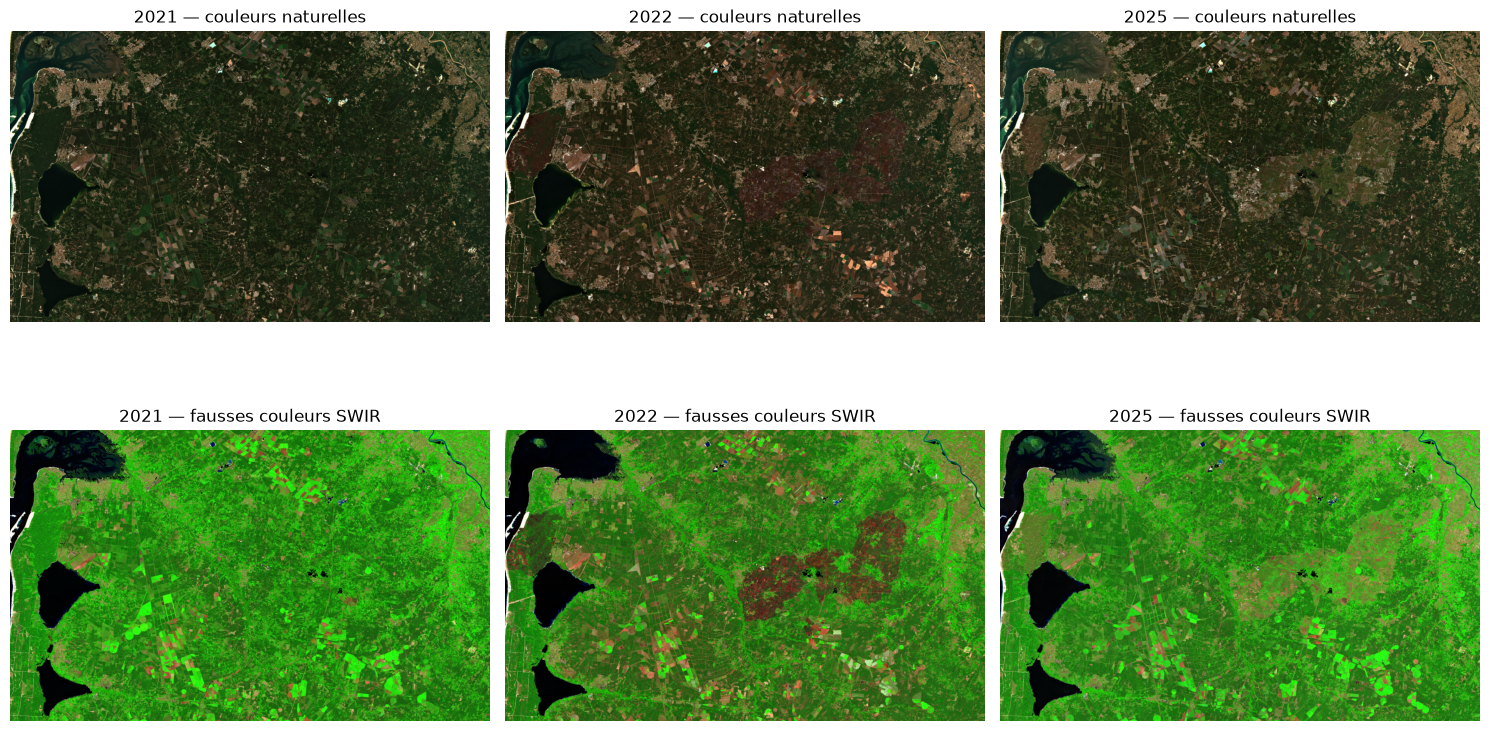

In [8]:
def rgb(ds, bandes, maxi):
    arr = np.stack([ds[b].values for b in bandes], axis=-1).astype("float32")
    arr = arr[::4, ::4]                     # sous-échantillonnage pour l'affichage
    return np.clip(arr / maxi, 0, 1)


fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, annee in enumerate(composites):
    axes[0, j].imshow(rgb(composites[annee], ["B04", "B03", "B02"], 2500))
    axes[0, j].set_title(f"{annee} — couleurs naturelles")
    axes[1, j].imshow(rgb(composites[annee], ["B12", "B08", "B04"], 4500))
    axes[1, j].set_title(f"{annee} — fausses couleurs SWIR")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "composites_2021_2022_2025.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Étiquettes ESA WorldCover 2021


In [9]:
wc_items = catalog.search(
    collections=["esa-worldcover"],
    bbox=BBOX,
    query={"esa_worldcover:product_version": {"eq": "2.0.0"}},
).item_collection()
print(f"{len(wc_items)} tuile(s) WorldCover 2021")

wc = odc.stac.load(
    wc_items,
    bands=["map"],
    geobox=GEOBOX,          # même grille que Sentinel-2
    chunks=CHUNKS,
    resampling="nearest",
)
etiquettes = wc["map"].max("time").astype("uint8").compute()   # fusion des tuiles

lab = etiquettes.rio.write_crs(CRS).rio.write_nodata(0)
lab.rio.to_raster(DATA_DIR / "worldcover_2021.tif", compress="deflate", tiled=True)
print("-> data/worldcover_2021.tif")

1 tuile(s) WorldCover 2021


/Users/yanismalou/ia changement climatique /.venv/lib/python3.11/site-packages/rasterio/warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


-> data/worldcover_2021.tif


## 8 bis. Périmètres officiels des feux 2022 (EFFIS)


In [10]:
params = {
    "service": "WFS", "version": "1.1.0", "request": "GetFeature",
    "typename": EFFIS_COUCHE, "srsName": "EPSG:4326", "outputformat": "geojson",
    # En WFS 1.1.0 avec EPSG:4326, l'ordre des coordonnées est latitude, longitude
    "bbox": f"{BBOX[1]},{BBOX[0]},{BBOX[3]},{BBOX[2]},EPSG:4326",
}
reponse = requests.get(EFFIS_WFS, params=params, timeout=600)
reponse.raise_for_status()
tous_les_feux = reponse.json()["features"]

fin_periode_2022 = PERIODES["2022"].split("/")[1]
feux = [f for f in tous_les_feux
        if f["properties"]["FIREDATE"][:4] == ANNEE_FEUX
        and f["properties"]["FIREDATE"][:10] <= fin_periode_2022]

with open(DATA_DIR / "feux_effis_2022.geojson", "w") as f:
    json.dump({"type": "FeatureCollection", "telecharge_le": str(date.today()),
               "source": f"{EFFIS_WFS} ({EFFIS_COUCHE})", "features": feux}, f)

tableau_feux = pd.DataFrame([{
    "commune": f["properties"]["COMMUNE"],
    "début": f["properties"]["FIREDATE"][:10],
    "fin": f["properties"]["FINALDATE"][:10],
    "surface_effis_ha": float(f["properties"]["AREA_HA"]),
    "résineux_%": round(float(f["properties"]["CONIFER"]), 1),
} for f in feux]).sort_values("surface_effis_ha", ascending=False)
print(f"{len(tous_les_feux)} périmètres EFFIS dans la zone, dont {len(feux)} feux de {ANNEE_FEUX}")
tableau_feux

22 périmètres EFFIS dans la zone, dont 7 feux de 2022


,commune,début,fin,surface_effis_ha,résineux_%
1,Louchats,2022-07-07,2022-07-19,13116.0,46.0
5,Belin-Béliet,2022-08-09,2022-08-11,7566.0,47.7
0,Teste-de-Buch,2022-07-12,2022-07-17,5806.0,88.4
3,Mano,2022-07-31,2022-08-01,313.0,45.8
6,Belin-Béliet,2022-08-10,2022-08-10,33.0,54.8
2,Sanguinet,2022-08-17,2022-08-18,17.0,17.6
4,Parentis-en-Born,2022-07-15,2022-07-16,15.0,0.0


**Rastérisation** : on transforme les polygones en une couche 0/1 sur **exactement la même grille** que les images (un pixel vaut 1 si son centre est dans un périmètre).

In [11]:
vers_utm = Transformer.from_crs("EPSG:4326", CRS, always_xy=True).transform
polygones = [transformer_geometrie(vers_utm, shape(f["geometry"])) for f in feux]

masque_feux = rasterize(
    ((p, 1) for p in polygones),
    out_shape=etiquettes.shape,
    transform=GEOBOX.transform,
    fill=0,
    dtype="uint8",
) if polygones else np.zeros(etiquettes.shape, dtype="uint8")

couche_feux = etiquettes.copy(data=masque_feux).rio.write_crs(CRS).rio.write_nodata(255)
couche_feux.rio.to_raster(DATA_DIR / "feux_effis_2022.tif", compress="deflate", tiled=True)
print(f"Surface rastérisée dans la zone : {masque_feux.sum() * RESOLUTION**2 / 10_000:,.0f} ha "
      f"(somme des surfaces EFFIS, y compris hors zone : {tableau_feux['surface_effis_ha'].sum():,.0f} ha)")
print("-> data/feux_effis_2022.tif")

Surface rastérisée dans la zone : 26,867 ha (somme des surfaces EFFIS, y compris hors zone : 26,866 ha)
-> data/feux_effis_2022.tif


## 8 ter. Pertes de couvert forestier (Hansen Global Forest Change)


In [12]:
hansen = rioxarray.open_rasterio("/vsicurl/" + HANSEN_URL).squeeze("band", drop=True)
hansen = hansen.rio.clip_box(*BBOX, crs="EPSG:4326").rio.write_nodata(0)
hansen = hansen.rio.reproject_match(lab, resampling=Resampling.nearest).fillna(0).astype("uint8")
hansen.rio.write_nodata(0).rio.to_raster(DATA_DIR / "hansen_perte_annee.tif", compress="deflate", tiled=True)
print("-> data/hansen_perte_annee.tif")

annees_perte = hansen.values
dans_feux = masque_feux == 1
pertes = pd.DataFrame({
    "année": 2000 + np.arange(18, 25),
    "perte_totale_ha": [(annees_perte == a).sum() * RESOLUTION**2 / 10_000 for a in range(18, 25)],
    "dont_dans_les_feux_2022_ha": [((annees_perte == a) & dans_feux).sum() * RESOLUTION**2 / 10_000 for a in range(18, 25)],
}).round(0)
pertes

-> data/hansen_perte_annee.tif


,année,perte_totale_ha,dont_dans_les_feux_2022_ha
0,2018,5719.0,467.0
1,2019,5329.0,520.0
2,2020,3782.0,381.0
3,2021,3538.0,346.0
4,2022,8232.0,5424.0
5,2023,9715.0,7171.0
6,2024,4005.0,587.0


## 9. Contrôle final

In [13]:
# Même grille partout ?
for annee, comp in composites.items():
    assert comp["B04"].shape == etiquettes.shape, f"Grille différente pour {annee}"
assert masque_feux.shape == etiquettes.shape
assert annees_perte.shape == etiquettes.shape
print("Grilles identiques :", etiquettes.shape, CRS)

# Les zones brûlées ont-elles autant d'observations valides que le reste ?
# (une surface calcinée très sombre peut être prise pour une ombre par le masque SCL)
dans_feux = masque_feux == 1
for annee, n_obs in n_obs_par_annee.items():
    v = n_obs.values
    if dans_feux.any():
        print(f"{annee} : obs. valides/pixel (médiane) dans les périmètres {np.median(v[dans_feux]):.0f}, "
              f"ailleurs {np.median(v[~dans_feux]):.0f}")

# Répartition des classes
NOMS_WC = {
    10: "Arbres", 20: "Arbustes", 30: "Prairies", 40: "Cultures", 50: "Bâti",
    60: "Sol nu / peu végétalisé", 70: "Neige / glace", 80: "Eau", 90: "Zones humides",
    95: "Mangroves", 100: "Mousses / lichens", 0: "Pas de donnée",
}
valeurs, comptes = np.unique(etiquettes.values, return_counts=True)
repartition = pd.DataFrame({
    "classe": valeurs,
    "nom": [NOMS_WC.get(int(v), "?") for v in valeurs],
    "pixels": comptes,
    "surface_ha": comptes * RESOLUTION**2 / 10_000,
    "part_%": (comptes / comptes.sum() * 100).round(2),
}).sort_values("pixels", ascending=False)
repartition

Grilles identiques : (4650, 7674) EPSG:32630
2021 : obs. valides/pixel (médiane) dans les périmètres 5, ailleurs 5


2022 : obs. valides/pixel (médiane) dans les périmètres 3, ailleurs 3


2025 : obs. valides/pixel (médiane) dans les périmètres 5, ailleurs 5


,classe,nom,pixels,surface_ha,part_%
0,10,Arbres,20765709,207657.09,58.19
2,30,Prairies,8005066,80050.66,22.43
3,40,Cultures,3288063,32880.63,9.21
6,80,Eau,2382719,23827.19,6.68
4,50,Bâti,984166,9841.66,2.76
7,90,Zones humides,129959,1299.59,0.36
5,60,Sol nu / peu végétalisé,125184,1251.84,0.35
1,20,Arbustes,3234,32.34,0.01


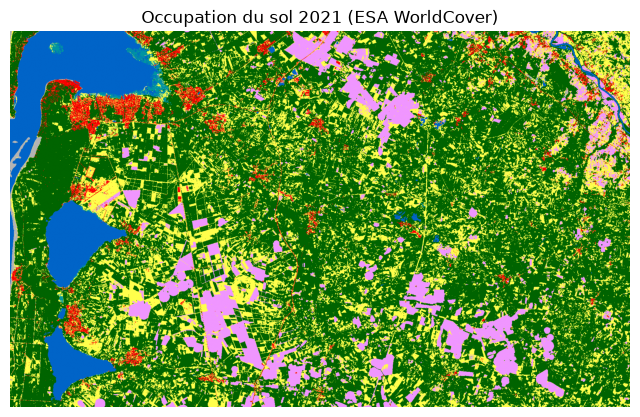

In [14]:
# Carte des étiquettes
couleurs = {10: "#006400", 20: "#ffbb22", 30: "#ffff4c", 40: "#f096ff", 50: "#fa0000",
            60: "#b4b4b4", 70: "#f0f0f0", 80: "#0064c8", 90: "#0096a0", 95: "#00cf75", 100: "#fae6a0"}
img = np.zeros(etiquettes.shape + (3,))
for v, c in couleurs.items():
    img[etiquettes.values == v] = [int(c[i:i+2], 16) / 255 for i in (1, 3, 5)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img[::4, ::4])
ax.set_title("Occupation du sol 2021 (ESA WorldCover)")
ax.axis("off")
plt.savefig(FIG_DIR / "worldcover_2021.png", dpi=200, bbox_inches="tight")
plt.show()

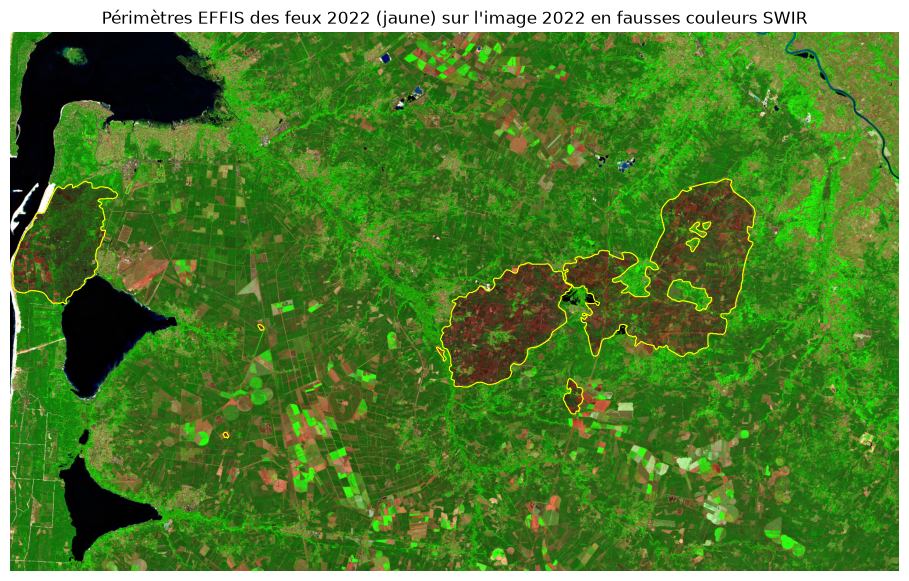

In [15]:
# Périmètres EFFIS sur l'image 2022 en fausses couleurs SWIR
pas = 4
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(rgb(composites["2022"], ["B12", "B08", "B04"], 4500))
ax.contour(masque_feux[::pas, ::pas], levels=[0.5], colors="yellow", linewidths=0.8)
ax.set_title("Périmètres EFFIS des feux 2022 (jaune) sur l'image 2022 en fausses couleurs SWIR")
ax.axis("off")
plt.savefig(FIG_DIR / "perimetres_effis_2022.png", dpi=200, bbox_inches="tight")
plt.show()